# Лабораторна 10. Завдання 4 — мультикласова класифікація Rock-Paper-Scissors

Курс «Глибокі нейронні мережі». Пункти 15–16 умови.

Перша в цих лабораторних задача **не на два класи, а на три**. Відмінностей від
бінарної класифікації рівно три, і всі вони в коді нижче:

| Що | Бінарна задача | Три класи |
|---|---|---|
| останній шар | `Dense(1, activation='sigmoid')` | `Dense(3, activation='softmax')` |
| функція втрат | `binary_crossentropy` | `categorical_crossentropy` |
| режим генератора | `class_mode='binary'` | `class_mode='categorical'` |

`softmax` масштабує виходи так, щоб вони давали в сумі 1 — тобто повертає
розподіл імовірностей за класами, а не одне число.

Архітектура й параметри навчання — з базового ноутбука
`Example_1_multi_class_classifier.ipynb` без змін. Дописано розпізнавання
набору з лекції (пункт 15) і власних фотографій рук (пункт 16).

Середовище, шляхи, перевірка GPU.

In [1]:
import json
import shutil
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print('TensorFlow', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
if IN_COLAB and not tf.config.list_physical_devices('GPU'):
    print('\n!! GPU НЕ УВІМКНЕНО. Середовище виконання -> Змінити тип -> ГП T4.')

LAB_ROOT = Path('/content') if IN_COLAB else Path.cwd().parent
RESULTS = LAB_ROOT / 'results'
(RESULTS / 'raw').mkdir(parents=True, exist_ok=True)

SEED = 42
INPUT_SIZE = 150
tf.keras.utils.set_random_seed(SEED)
print('Результати:', RESULTS)

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Результати: /content/results


Набір Rock-Paper-Scissors: три архіви з
`storage.googleapis.com/learning-datasets` — навчальний, тестовий і невеликий
набір для перевірки розпізнавання, наведений у лекції.

In [2]:
# Набір Rock-Paper-Scissors: згенеровані зображення рук на білому тлі.
# Три архіви: навчальний, тестовий і окремий невеликий набір для перевірки
# розпізнавання — саме той, що наведений у лекції.
BASE = Path('/content') if IN_COLAB else LAB_ROOT / 'data'
BASE.mkdir(parents=True, exist_ok=True)

ARCHIVES = {
    'rps.zip': 'rps-train',
    'rps-test-set.zip': 'rps-test',
    'rps-validation.zip': 'rps-validation',
}

import urllib.request

for _name, _dest in ARCHIVES.items():
    _target = BASE / _dest
    if _target.exists():
        continue
    _zip = BASE / _name
    if not _zip.exists():
        _url = f'https://storage.googleapis.com/learning-datasets/{_name}'
        print('завантажую', _name)
        urllib.request.urlretrieve(_url, _zip)
    with zipfile.ZipFile(_zip) as z:
        z.extractall(_target)
    print(f'{_name} -> {_dest}')

TRAIN_DIR = BASE / 'rps-train' / 'rps'
TEST_DIR = BASE / 'rps-test' / 'rps-test-set'
# rps-validation розпаковується у плаский каталог із файлами без підпапок.
VALID_DIR = BASE / 'rps-validation'

for _n, _d in (('навчальний', TRAIN_DIR), ('тестовий', TEST_DIR)):
    _counts = {p.name: len(list(p.glob('*.png'))) for p in sorted(_d.iterdir())
               if p.is_dir()}
    print(f'{_n}: {_counts}, разом {sum(_counts.values())}')

_loose = sorted(p for p in VALID_DIR.rglob('*.png') if p.is_file())
print(f'набір із лекції: {len(_loose)} зображень')

завантажую rps.zip
rps.zip -> rps-train
завантажую rps-test-set.zip
rps-test-set.zip -> rps-test
завантажую rps-validation.zip
rps-validation.zip -> rps-validation
навчальний: {'paper': 840, 'rock': 840, 'scissors': 840}, разом 2520
тестовий: {'paper': 124, 'rock': 124, 'scissors': 124}, разом 372
набір із лекції: 33 зображень


Генератори. Аугментація — лише для навчального набору.

In [3]:
# Генератори — точно як у базовому ноутбуці: аугментація для навчального
# набору, лише нормалізація для перевірочного.
#
# class_mode='categorical' і softmax на виході — це головна відмінність від
# бінарних задач попередніх лабораторних: класів три, а не два.
training_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest')

validation_datagen = ImageDataGenerator(rescale=1./255)

train_generator = training_datagen.flow_from_directory(
    TRAIN_DIR, target_size=(INPUT_SIZE, INPUT_SIZE),
    class_mode='categorical', batch_size=126)

validation_generator = validation_datagen.flow_from_directory(
    TEST_DIR, target_size=(INPUT_SIZE, INPUT_SIZE),
    class_mode='categorical', batch_size=126)

CLASS_NAMES = {v: k for k, v in train_generator.class_indices.items()}
UA = {'paper': 'папір', 'rock': 'камінь', 'scissors': 'ножиці'}
print('\nкласи:', train_generator.class_indices)
print('порядок виходу softmax:', [CLASS_NAMES[i] for i in range(len(CLASS_NAMES))])

Found 2520 images belonging to 3 classes.
Found 372 images belonging to 3 classes.

класи: {'paper': 0, 'rock': 1, 'scissors': 2}
порядок виходу softmax: ['paper', 'rock', 'scissors']


Модель із базового ноутбука: чотири згорткові шари 64-64-128-128.

In [4]:
# Архітектура з базового ноутбука: чотири згорткові шари 64-64-128-128,
# Dropout проти перенавчання, і Dense(3, softmax) — по нейрону на клас.
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(INPUT_SIZE, INPUT_SIZE, 3)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax'),
])

# categorical_crossentropy замість binary_crossentropy — бо класів більше двох.
model.compile(loss='categorical_crossentropy', optimizer='rmsprop',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         1,539 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,473,475 (13.25 MB)

 Trainable params: 3,473,475 (13.25 MB)

 Non-trainable params: 0 (0.00 B)

Навчання, 25 епох.

In [5]:
t0 = time.time()
history = model.fit(train_generator, epochs=25, steps_per_epoch=20,
                    validation_data=validation_generator, verbose=1,
                    validation_steps=3)
train_time = time.time() - t0
print(f'\nнавчання: {train_time / 60:.1f} хв')

Epoch 1/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.3524 - loss: 1.1239 - val_accuracy: 0.3333 - val_loss: 1.0971
Epoch 2/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 972ms/step - accuracy: 0.3643 - loss: 1.0985 - val_accuracy: 0.3333 - val_loss: 1.0911
Epoch 3/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 994ms/step - accuracy: 0.4008 - loss: 1.0809 - val_accuracy: 0.6640 - val_loss: 0.9001
Epoch 4/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 966ms/step - accuracy: 0.4968 - loss: 1.0284 - val_accuracy: 0.9866 - val_loss: 0.5938
Epoch 5/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 996ms/step - accuracy: 0.5956 - loss: 0.8415 - val_accuracy: 0.6183 - val_loss: 0.7316
Epoch 6/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 967ms/step - accuracy: 0.6520 - loss: 0.7576 - val_accuracy: 0.9516 - val_loss: 0.3144
Epoch 7/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.7143 - loss: 0.6599 - val_accuracy: 0.9489 - val_loss: 0.3072
Epoch 8/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 976ms/step - accuracy: 0.7591 - loss: 0.5646 - val_accuracy: 

Криві навчання й оцінка на тестовому наборі.

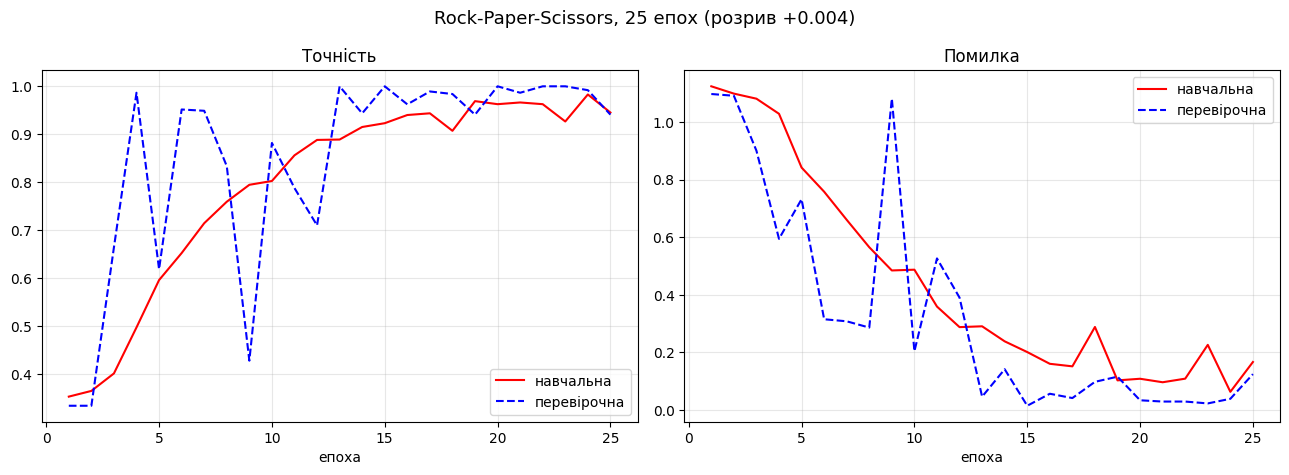

тестовий набір: accuracy 0.9409, loss 0.1236


In [6]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(epochs_range, acc, 'r-', label='навчальна')
ax1.plot(epochs_range, val_acc, 'b--', label='перевірочна')
ax1.set_title('Точність')
ax2.plot(epochs_range, loss, 'r-', label='навчальна')
ax2.plot(epochs_range, val_loss, 'b--', label='перевірочна')
ax2.set_title('Помилка')
for ax in (ax1, ax2):
    ax.set_xlabel('епоха')
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle(f'Rock-Paper-Scissors, 25 епох (розрив {acc[-1] - val_acc[-1]:+.3f})',
             fontsize=13)
plt.tight_layout()
plt.savefig(RESULTS / 'task4_history.png', dpi=110, bbox_inches='tight')
plt.show()

test_loss, test_acc = model.evaluate(validation_generator, verbose=0)
print(f'тестовий набір: accuracy {test_acc:.4f}, loss {test_loss:.4f}')

Функція розпізнавання, спільна для набору з лекції і власних фото.

In [7]:
# Спільна функція розпізнавання для обох наборів.
#
# Клас визначається з імені файлу: у наборі з лекції файли названі
# paper1.png, rock3.png, scissors2.png; у власних фото клас задає тека.
def predict_images(paths, labels, title, fname, size=INPUT_SIZE):
    """Повертає список результатів і малює сітку з прогнозами."""
    batch = np.vstack([
        np.expand_dims(img_to_array(load_img(p, target_size=(size, size))) / 255.0, 0)
        for p in paths
    ])
    probs = model.predict(batch, verbose=0)

    records = []
    for p, label, row in zip(paths, labels, probs):
        pred_idx = int(np.argmax(row))
        pred = CLASS_NAMES[pred_idx]
        records.append({
            'file': p.name, 'predicted': pred, 'actual': label,
            'correct': pred == label, 'confidence': float(row[pred_idx]),
            'probs': {CLASS_NAMES[i]: float(v) for i, v in enumerate(row)},
        })

    cols = 5
    rows = (len(records) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(2.9 * cols, 3.4 * rows))
    for ax, p, r in zip(np.atleast_1d(axes).ravel(), paths, records):
        ax.imshow(load_img(p, target_size=(size, size)))
        ax.set_title(f"{UA[r['predicted']]} {r['confidence']:.0%}\n"
                     f"факт: {UA[r['actual']]} {'+' if r['correct'] else 'ПОМИЛКА'}",
                     fontsize=8, color='green' if r['correct'] else 'crimson')
        ax.axis('off')
    for ax in np.atleast_1d(axes).ravel()[len(records):]:
        ax.axis('off')
    good = sum(r['correct'] for r in records)
    fig.suptitle(f'{title}: {good} з {len(records)}', fontsize=13)
    plt.tight_layout()
    plt.savefig(RESULTS / fname, dpi=110, bbox_inches='tight')
    plt.show()
    return records

**Пункт 15.** До 10 тестових зображень із набору, наведеного в лекції.

вибірка: {'paper': 4, 'rock': 3, 'scissors': 3}


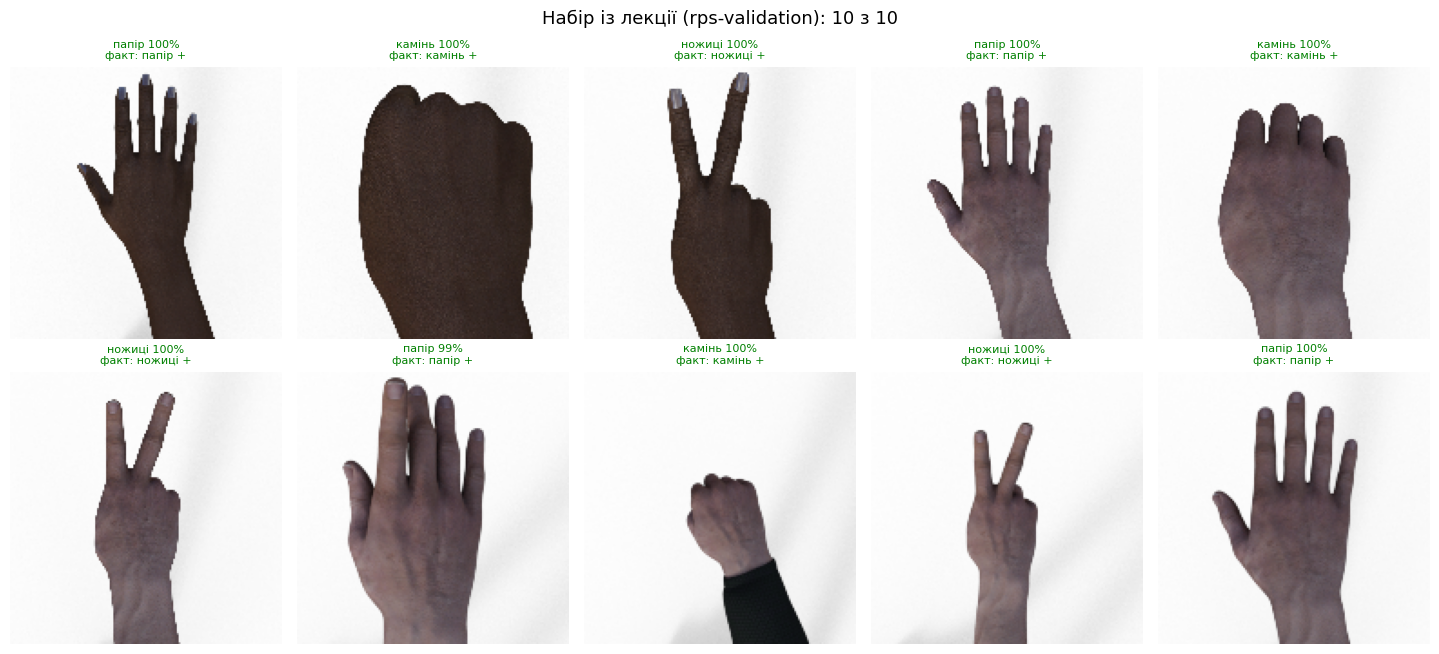


файл                 прогноз    факт        впевненість
--------------------------------------------------------
paper-hires1.png     папір      папір           100.0%
rock-hires1.png      камінь     камінь          100.0%
scissors-hires1.png  ножиці     ножиці          100.0%
paper-hires2.png     папір      папір           100.0%
rock-hires2.png      камінь     камінь          100.0%
scissors-hires2.png  ножиці     ножиці          100.0%
paper1.png           папір      папір            99.5%
rock1.png            камінь     камінь          100.0%
scissors1.png        ножиці     ножиці          100.0%
paper2.png           папір      папір           100.0%


In [8]:
# Пункт 15: до 10 тестових зображень із набору, наведеного в лекції.
#
# Файли названі paper1.png, rock-hires2.png тощо, тож клас читається з імені.
# Беремо їх по колу, а не перші десять за алфавітом: інакше у вибірку
# потрапив би самий лише «папір» і перевірка нічого б не показала.
CLASSES = ('paper', 'rock', 'scissors')
_by_class = {c: [] for c in CLASSES}
for _p in sorted(p for p in VALID_DIR.rglob('*.png') if p.is_file()):
    _cls = next((c for c in CLASSES if _p.stem.lower().startswith(c)), None)
    if _cls:
        _by_class[_cls].append(_p)

_files, _labels = [], []
for _i in range(max(len(v) for v in _by_class.values())):
    for _cls in CLASSES:
        if _i < len(_by_class[_cls]) and len(_files) < 10:
            _files.append(_by_class[_cls][_i])
            _labels.append(_cls)

print('вибірка:', {c: _labels.count(c) for c in CLASSES})

lecture = predict_images(_files, _labels, 'Набір із лекції (rps-validation)',
                         'task4_lecture_images.png')

print(f"\n{'файл':<20} {'прогноз':<10} {'факт':<10} {'впевненість':>12}")
print('-' * 56)
for _r in lecture:
    _mark = '' if _r['correct'] else '   <-- помилка'
    print(f"{_r['file']:<20} {UA[_r['predicted']]:<10} {UA[_r['actual']]:<10} "
          f"{_r['confidence']:>11.1%}{_mark}")

**Пункт 16.** Власні фотографії рук.

Потрібні ваші фото — їх ніде взяти. По 3–4 знімки кожного жесту покласти у
`lab10/my_images/rps/rock/`, `.../paper/`, `.../scissors/`, запустити
`scripts/pack_my_images.py` і залити `my_images.zip` у `MyDrive/dl_lab10/`.

Mounted at /content/drive
paper      3 фото
rock       3 фото
scissors   3 фото


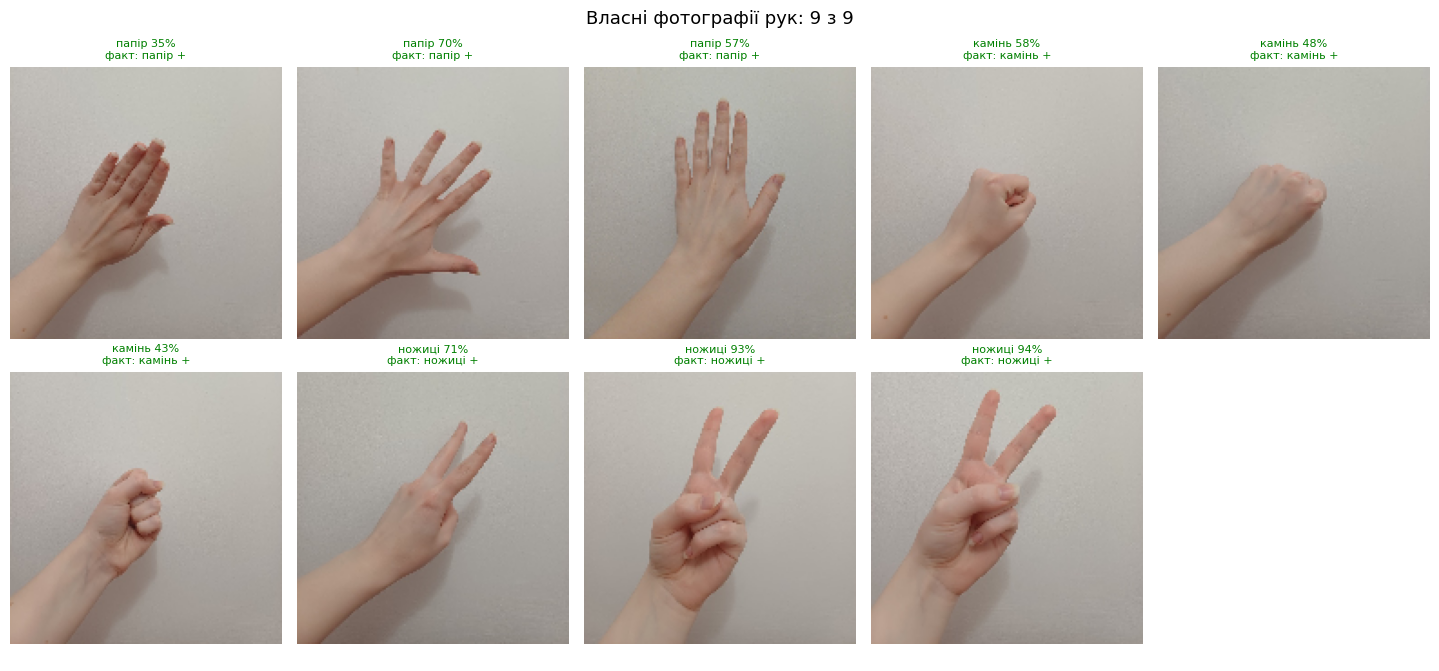

In [10]:
# Пункт 16: власні фотографії рук.
#
# Набір RPS складається зі згенерованих зображень рук на рівному білому тлі,
# а телефонне фото має кімнатне тло, тіні й інший колір шкіри. Саме тому
# якість на реальних фото зазвичай помітно нижча — це і є суть пункту.
MY_IMAGES = Path('/content/my_images') if IN_COLAB else LAB_ROOT / 'my_images'
if IN_COLAB and not MY_IMAGES.exists():
    from google.colab import drive

    drive.mount('/content/drive')
    _src = Path('/content/drive/MyDrive/dl_lab10/my_images.zip')
    if not _src.exists():
        raise FileNotFoundError(f'немає {_src} — залийте my_images.zip у MyDrive/dl_lab10/')
    with zipfile.ZipFile(_src) as z:
        z.extractall(MY_IMAGES)

RPS_DIR = MY_IMAGES / 'rps'
_paths, _labels = [], []
for _cls in ('paper', 'rock', 'scissors'):
    _d = RPS_DIR / _cls
    _found = sorted(p for p in _d.glob('*') if p.suffix.lower() in
                    {'.jpg', '.jpeg', '.png'}) if _d.is_dir() else []
    print(f'{_cls:<10} {len(_found)} фото')
    _paths += _found
    _labels += [_cls] * len(_found)

if not _paths:
    raise FileNotFoundError(
        f'у {RPS_DIR} немає фотографій.\n'
        'Зніміть по 3-4 фото кожного жесту, покладіть у lab10/my_images/rps/<клас>/,\n'
        'перезапустіть scripts/pack_my_images.py і перезалийте my_images.zip на Drive.')

own = predict_images(_paths, _labels, 'Власні фотографії рук',
                     'task4_own_images.png')

**Пункт 16.** Чи змінилась якість на реальних фотографіях?

Набір RPS — це згенеровані зображення рук на рівному білому тлі. Телефонне
фото має кімнатне тло, тіні й інший колір шкіри, тож мережа бачить розподіл,
на якому її не вчили. Матриця помилок показує, які саме жести плутаються.

набір                         вгадано    частка   сер. впевненість
--------------------------------------------------------------------
тестовий (згенерований)         10/10     100%             99.9%
власні фото                       9/9     100%             63.2%

Помилки на власних фото:
  немає


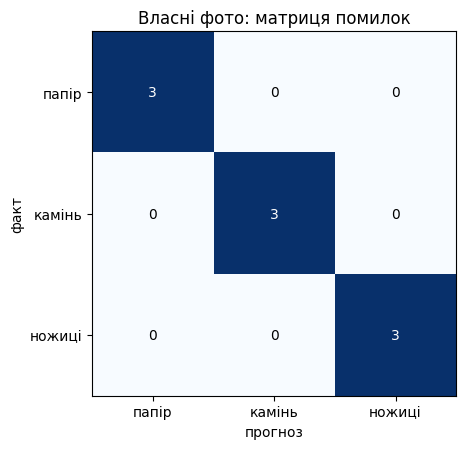

In [11]:
# Пункт 16: чи змінилась якість на реальних фотографіях?
_lec_ok = sum(r['correct'] for r in lecture)
_own_ok = sum(r['correct'] for r in own)
_lec_conf = np.mean([r['confidence'] for r in lecture])
_own_conf = np.mean([r['confidence'] for r in own])

print(f"{'набір':<26} {'вгадано':>10} {'частка':>9} {'сер. впевненість':>18}")
print('-' * 68)
print(f"{'тестовий (згенерований)':<26} {f'{_lec_ok}/{len(lecture)}':>10} "
      f"{_lec_ok / len(lecture):>8.0%} {_lec_conf:>17.1%}")
print(f"{'власні фото':<26} {f'{_own_ok}/{len(own)}':>10} "
      f"{_own_ok / len(own):>8.0%} {_own_conf:>17.1%}")

print('\nПомилки на власних фото:')
_errors = [r for r in own if not r['correct']]
if not _errors:
    print('  немає')
for _r in _errors:
    _top = sorted(_r['probs'].items(), key=lambda kv: -kv[1])
    print(f"  {_r['file']:<24} сказано {UA[_r['predicted']]}, а це {UA[_r['actual']]}")
    print('      ' + ', '.join(f'{UA[k]} {v:.0%}' for k, v in _top))

# Матриця помилок на власних фото: видно, які жести плутаються між собою.
_order = ['paper', 'rock', 'scissors']
_cm = np.zeros((3, 3), dtype=int)
for _r in own:
    _cm[_order.index(_r['actual']), _order.index(_r['predicted'])] += 1

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.imshow(_cm, cmap='Blues')
ax.set_xticks(range(3), [UA[c] for c in _order])
ax.set_yticks(range(3), [UA[c] for c in _order])
ax.set_xlabel('прогноз')
ax.set_ylabel('факт')
for _i in range(3):
    for _j in range(3):
        ax.text(_j, _i, _cm[_i, _j], ha='center', va='center',
                color='white' if _cm[_i, _j] > _cm.max() / 2 else 'black')
ax.set_title('Власні фото: матриця помилок')
plt.tight_layout()
plt.savefig(RESULTS / 'task4_own_confusion.png', dpi=110, bbox_inches='tight')
plt.show()

Експорт результатів і збереження моделі.

Зіп покласти у `dl/lab10/results/incoming/`, ноутбук — у `dl/lab10/notebooks/`.

In [12]:
metrics = {
    'task': 'task4_rock_paper_scissors',
    'seed': SEED, 'input_size': INPUT_SIZE, 'tensorflow': tf.__version__,
    'classes': train_generator.class_indices,
    'epochs': len(acc),
    'total_params': int(model.count_params()),
    'final_train_accuracy': float(acc[-1]),
    'final_val_accuracy': float(val_acc[-1]),
    'overfit_gap': float(acc[-1] - val_acc[-1]),
    'test_accuracy': float(test_acc),
    'test_loss': float(test_loss),
    'train_time_sec': round(train_time, 1),
    'history': {k: [float(x) for x in v] for k, v in history.history.items()},
    'lecture_images': lecture,
    'lecture_correct': sum(r['correct'] for r in lecture),
    'lecture_total': len(lecture),
    'own_images': own,
    'own_correct': sum(r['correct'] for r in own),
    'own_total': len(own),
}
out = RESULTS / 'raw' / 'task4.json'
out.write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')
print('Збережено', out)

model_path = RESULTS / 'task4_rps.keras'
model.save(model_path)
print(f'{model_path.name} — {model_path.stat().st_size / 1e6:.1f} МБ')

if IN_COLAB:
    _drive = Path('/content/drive/MyDrive/dl_lab10')
    (_drive / 'models').mkdir(parents=True, exist_ok=True)
    (_drive / 'results').mkdir(parents=True, exist_ok=True)
    shutil.copy(model_path, _drive / 'models' / model_path.name)

zip_path = (Path('/content') if IN_COLAB else RESULTS) / 'lab10_task4_results.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for _p in sorted(RESULTS.rglob('*')):
        if _p.is_file() and 'task4' in _p.name and _p.suffix != '.keras':
            z.write(_p, _p.relative_to(RESULTS))
print(zip_path, f'{zip_path.stat().st_size / 1e6:.2f} МБ')

if IN_COLAB:
    shutil.copy(zip_path, _drive / 'results' / zip_path.name)
    from google.colab import files

    files.download(str(zip_path))

Збережено /content/results/raw/task4.json
task4_rps.keras — 27.8 МБ
/content/lab10_task4_results.zip 1.08 МБ


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>